# Medical image classification that knows when not to predict: analysis

A triage model for medical images should answer the cases it is sure about and hand the rest to a clinician. This
notebook asks whether a fine-tuned ResNet-18 can do that on two MedMNIST+ data sets at 64 x 64 pixels:
DermaMNIST (dermatoscopic skin lesions, 7 classes, 67% nevi) and BloodMNIST (blood-cell microscopy, 8 classes).

| Part | Question | Validation |
|---|---|---|
| Data | Do the files match the published data sets? | MD5 digests, split sizes and licences against the paper and `medmnist.info` |
| Benchmark | Does the pipeline reach the published accuracy? | MedMNIST v2 ResNet-18 baselines; a frozen-feature linear probe as the baseline to beat |
| Calibration | Do confidences mean what they say? | ECE, NLL, reliability diagrams; paired bootstrap, Holm correction |
| Selective prediction | How accurate are the answered images when uncertain ones are deferred? | risk-coverage curves, AURC, oracle bound |
| Shift | Does deferral still protect under corruption and on foreign images? | four corruptions x five severities with a threshold fixed on clean data; the other data set as out-of-distribution |
| Imbalance | Which classes get deferred, and what does rebalancing cost? | per-class recall and deferral |
| Grad-CAM | Do the explanations depend on the model? | cascading randomisation (Adebayo et al., 2018) |

Six uncertainty methods are compared: the softmax of one model, MC dropout (50 passes through the dropout head) and a
5-member deep ensemble, each with and without temperature scaling. Everything below reads the tables written by
`scripts/run_pipeline.py`. Run settings:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 180)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta[k] for k in ['train_config', 'timings_s', 'device']}

{'train_config': {'lr': 0.0005,
  'weight_decay': 0.0001,
  'batch_size': 128,
  'max_epochs': 12,
  'patience': 3,
  'dropout': 0.5,
  'class_weight_power': 0.0,
  'pretrained': True},
 'timings_s': {'data': 1.8,
  'linear probe': 0.0,
  'inference': 0.3,
  'evaluation': 34.7,
  'grad-cam': 11.2},
 'device': 'NVIDIA GeForce RTX 4050 Laptop GPU'}

## 1. Data and checks

Both 64-pixel MedMNIST+ files match the MD5 digests that the `medmnist` package publishes, and the split sizes,
number of classes and licences match the MedMNIST v2 paper and the package metadata (20 of 20 checks).
DermaMNIST is strongly imbalanced: 67% of training images are melanocytic nevi, 1.1% dermatofibromas. BloodMNIST's
classes range from 7% to 19%.

In [2]:
pd.read_csv(RES / 'data_crosscheck.csv')

,dataset,statistic,published,observed,match,source
0,dermamnist,train,7007,7007,True,MedMNIST v2 paper (Table 1) vs loaded arrays
1,dermamnist,val,1003,1003,True,MedMNIST v2 paper (Table 1) vs loaded arrays
2,dermamnist,test,2005,2005,True,MedMNIST v2 paper (Table 1) vs loaded arrays
3,dermamnist,classes,7,7,True,MedMNIST v2 paper (Table 1) vs loaded arrays
4,bloodmnist,train,11959,11959,True,MedMNIST v2 paper (Table 1) vs loaded arrays
5,bloodmnist,val,1712,1712,True,MedMNIST v2 paper (Table 1) vs loaded arrays
6,bloodmnist,test,3421,3421,True,MedMNIST v2 paper (Table 1) vs loaded arrays
7,bloodmnist,classes,8,8,True,MedMNIST v2 paper (Table 1) vs loaded arrays
8,dermamnist,MD5 of dermamnist_64.npz,b70a2f5635c6199aeaa28c31d7202e1f,b70a2f5635c6199aeaa28c31d7202e1f,True,medmnist.info.INFO vs this project's pinned values
9,dermamnist,license,CC BY-NC 4.0,CC BY-NC 4.0,True,medmnist.info.INFO vs this project's pinned values


In [3]:
pd.read_csv(RES / 'class_counts.csv').pivot_table(index=['dataset', 'short'], values=['train', 'val', 'test', 'train_share'], sort=False)

train    val    test  train_share
dataset    short                                    
dermamnist akiec   228.0   33.0    66.0        0.033
           bcc     359.0   52.0   103.0        0.051
           bkl     769.0  110.0   220.0        0.110
           df       80.0   12.0    23.0        0.011
           mel     779.0  111.0   223.0        0.111
           nv     4693.0  671.0  1341.0        0.670
           vasc     99.0   14.0    29.0        0.014
bloodmnist baso    852.0  122.0   244.0        0.071
           eosi   2181.0  312.0   624.0        0.182
           eryth  1085.0  155.0   311.0        0.091
           ig     2026.0  290.0   579.0        0.169
           lymph   849.0  122.0   243.0        0.071
           mono    993.0  143.0   284.0        0.083
           neut   2330.0  333.0   666.0        0.195
           plt    1643.0  235.0   470.0        0.137

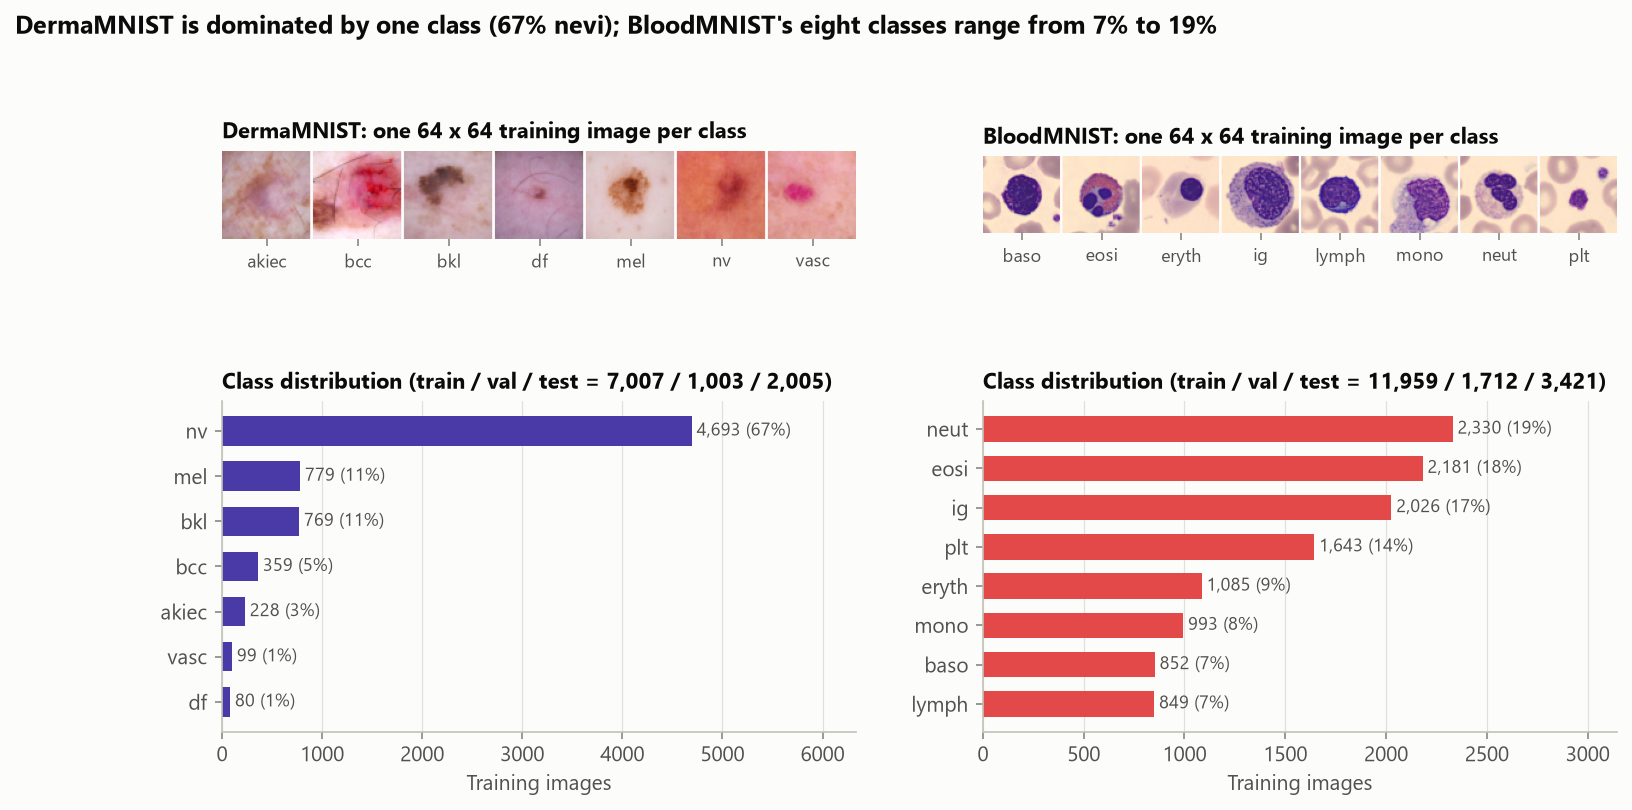

In [4]:
display(Image(FIG / '00_data.png'))

## 2. Training the ensemble members

Each data set gets five ResNet-18 members (ImageNet weights, dropout 0.5 before the classifier) that differ only in
their seed; DermaMNIST also gets one class-weighted member for the imbalance comparison. Members train for at most 12
epochs and keep the epoch with the lowest validation NLL. DermaMNIST members reach 81.3-83.2% test accuracy,
BloodMNIST members 98.3-98.8%.

Temperatures fitted on validation NLL: the DermaMNIST single model is overconfident (T = 1.30), the five-member
average already calibrated (T = 0.98). On BloodMNIST the ensemble is slightly underconfident (T = 0.77).

In [5]:
pd.read_csv(RES / 'members.csv')

,dataset,member,seed,epochs_run,best_epoch,val_nll,val_acc,train_seconds,test_acc,test_nll
0,dermamnist,plain,0,12,9,0.468,0.834,26.419,0.831,0.485
1,dermamnist,plain,1,9,6,0.495,0.816,10.554,0.813,0.510
2,dermamnist,plain,2,11,8,0.480,0.833,12.912,0.818,0.484
3,dermamnist,plain,3,12,10,0.504,0.824,14.132,0.832,0.475
4,dermamnist,plain,4,10,7,0.489,0.825,11.812,0.822,0.476
5,dermamnist,weighted,0,12,10,0.746,0.806,29.140,0.807,0.529
6,bloodmnist,plain,0,12,12,0.029,0.990,30.099,0.987,0.048
7,bloodmnist,plain,1,12,10,0.028,0.994,24.564,0.987,0.042
8,bloodmnist,plain,2,12,11,0.025,0.993,24.622,0.987,0.045
9,bloodmnist,plain,3,7,4,0.038,0.988,14.438,0.983,0.055


In [6]:
pd.read_csv(RES / 'temperatures.csv')

,dataset,method,temperature
0,dermamnist,Single model,1.296
1,dermamnist,MC dropout,1.232
2,dermamnist,Deep ensemble,0.982
3,dermamnist,Class-weighted loss,1.330
4,bloodmnist,Single model,1.085
5,bloodmnist,MC dropout,1.030
6,bloodmnist,Deep ensemble,0.770


## 3. Benchmark check

The published MedMNIST v2 ResNet-18 baselines reach 0.735-0.754 accuracy on DermaMNIST and 0.958-0.963 on
BloodMNIST. They were trained on 28-pixel images (or 28-pixel images upsampled to 224) for 100 epochs; the paper does
not describe ImageNet pretraining. The fine-tuned 64-pixel models here land above that level (0.831 and 0.987), and a
logistic regression on frozen ImageNet features lands near it on DermaMNIST (0.751) and below it on BloodMNIST
(0.880), so fine-tuning matters. The comparison checks that the pipeline is sane rather than claiming a like-for-like
improvement; DermaMNIST is also known to leak images of the same lesion across splits (see the README).

In [7]:
pd.read_csv(RES / 'published_comparison.csv')

,dataset,model,source,resolution,auc,accuracy
0,dermamnist,ResNet-18 (28),"MedMNIST v2 (Yang et al., 2023)",28,0.917,0.735
1,dermamnist,ResNet-18 (224),"MedMNIST v2 (Yang et al., 2023)",224,0.920,0.754
2,dermamnist,ResNet-50 (28),"MedMNIST v2 (Yang et al., 2023)",28,0.913,0.735
3,dermamnist,ResNet-50 (224),"MedMNIST v2 (Yang et al., 2023)",224,0.912,0.731
4,dermamnist,Google AutoML Vision,"MedMNIST v2 (Yang et al., 2023)",28,0.914,0.768
5,dermamnist,"Linear probe (frozen ImageNet features), this project",this project,64,0.915,0.751
6,dermamnist,"Single model, this project",this project,64,0.965,0.831
7,dermamnist,"Deep ensemble + TS, this project",this project,64,0.971,0.842
8,bloodmnist,ResNet-18 (28),"MedMNIST v2 (Yang et al., 2023)",28,0.998,0.958
9,bloodmnist,ResNet-18 (224),"MedMNIST v2 (Yang et al., 2023)",224,0.998,0.963


## 4. The six methods on the clean test sets

- **DermaMNIST.** The deep ensemble is the best on every ranking metric: accuracy 0.842 vs 0.831, AUC 0.971 vs 0.965,
  NLL 0.415 vs 0.485 and AURC 3.51% vs 4.14% for the single model, and it reaches 90% accuracy while answering 89% of
  the images instead of 84%. AUC, NLL and AURC differences are significant after Holm correction over 70 tests; the
  accuracy gain (+0.011, unadjusted p = 0.03) is not.
- **Temperature scaling** halves the single model's ECE (5.1% to 2.3%) and lowers NLL, without changing accuracy or
  AURC.
- **MC dropout** with 50 passes is indistinguishable from the temperature-scaled single model on every metric.
- **BloodMNIST** is near the ceiling (98.7-99.0% accuracy, 34-44 test errors); no paired difference survives the
  correction.

In [8]:
res = pd.read_csv(RES / 'method_results.csv')
cols = ['dataset', 'method', 'accuracy', 'balanced_accuracy', 'auc', 'nll', 'brier', 'ece', 'aurc', 'oracle_aurc',
        'error_detection_auroc', 'selective_acc_80', 'coverage_at_target']
res[cols]

,dataset,method,accuracy,balanced_accuracy,auc,nll,brier,ece,aurc,oracle_aurc,error_detection_auroc,selective_acc_80,coverage_at_target
0,dermamnist,Single model,0.831,0.689,0.965,0.485,0.245,0.051,0.041,1.522e-02,0.862,0.911,0.835
1,dermamnist,Single model + TS,0.831,0.689,0.965,0.460,0.239,0.023,0.041,1.522e-02,0.863,0.909,0.832
2,dermamnist,MC dropout,0.829,0.685,0.965,0.473,0.243,0.042,0.041,1.559e-02,0.866,0.911,0.835
3,dermamnist,MC dropout + TS,0.829,0.685,0.965,0.459,0.239,0.019,0.041,1.559e-02,0.867,0.910,0.833
4,dermamnist,Deep ensemble,0.842,0.693,0.971,0.415,0.218,0.026,0.035,1.317e-02,0.877,0.926,0.889
5,dermamnist,Deep ensemble + TS,0.842,0.693,0.971,0.415,0.218,0.025,0.035,1.317e-02,0.877,0.926,0.888
6,dermamnist,Linear probe (frozen ImageNet features),0.751,0.434,0.915,0.663,0.335,0.027,0.084,3.398e-02,0.835,0.839,0.649
7,bloodmnist,Single model,0.987,0.986,0.999,0.048,0.021,0.006,0.002,8.495e-05,0.931,0.999,0.994
8,bloodmnist,Single model + TS,0.987,0.986,0.999,0.046,0.021,0.005,0.002,8.495e-05,0.931,0.999,0.994
9,bloodmnist,MC dropout,0.987,0.986,0.999,0.046,0.021,0.006,0.002,8.882e-05,0.933,0.999,0.994


In [9]:
sig = pd.read_csv(RES / 'significance.csv')
sig.pivot_table(index=['dataset', 'method', 'versus'], columns='metric', values='diff', sort=False).round(4)

metric                                            accuracy        auc    nll        ece       aurc
dataset    method             versus                                                              
dermamnist Single model + TS  Single model       0.000e+00  1.000e-04 -0.025 -2.870e-02 -2.000e-04
           MC dropout         Single model      -2.000e-03  4.000e-04 -0.012 -9.600e-03  1.000e-04
           MC dropout + TS    Single model      -2.000e-03  4.000e-04 -0.026 -3.260e-02 -1.000e-04
                              Single model + TS -2.000e-03  3.000e-04 -0.001 -4.000e-03  1.000e-04
           Deep ensemble      Single model       1.150e-02  6.300e-03 -0.070 -2.590e-02 -6.300e-03
           Deep ensemble + TS Single model       1.150e-02  6.300e-03 -0.070 -2.680e-02 -6.300e-03
                              Single model + TS  1.150e-02  6.300e-03 -0.046  1.800e-03 -6.100e-03
bloodmnist Single model + TS  Single model       0.000e+00  0.000e+00 -0.002 -8.000e-04 -0.000e+00
           MC dropout         Single model      -3.000e-04  0.000e+00 -0.002 -3.000e-04  1.000e-04
           MC dropout + TS    Single model      -3.000e-04  0.000e+00 -0.003 -9.000e-04  1.000e-04
                              Single model + TS -3.000e-04  0.000e+00 -0.001 -1.000e-04  1.000e-04
           Deep ensemble      Single model       2.900e-03  1.000e-04 -0.009 -2.100e-03 -8.000e-04
           Deep ensemble + TS Single model       2.900e-03  1.000e-04 -0.006 -8.000e-04 -8.000e-04
                              Single model + TS  2.900e-03  1.000e-04 -0.004 -0.000e+00 -8.000e-04

In [10]:
sig[['dataset', 'method', 'versus', 'metric', 'diff', 'diff_ci_low', 'diff_ci_high', 'p_holm']].query('p_holm < 0.05').round(4)

,dataset,method,versus,metric,diff,diff_ci_low,diff_ci_high,p_holm
2,dermamnist,Single model + TS,Single model,nll,-0.025,-0.035,-0.016,0.000e+00
3,dermamnist,Single model + TS,Single model,ece,-0.029,-0.036,-0.013,1.200e-03
7,dermamnist,MC dropout,Single model,nll,-0.012,-0.015,-0.008,0.000e+00
12,dermamnist,MC dropout + TS,Single model,nll,-0.026,-0.036,-0.017,0.000e+00
13,dermamnist,MC dropout + TS,Single model,ece,-0.033,-0.037,-0.016,0.000e+00
16,dermamnist,Deep ensemble,Single model,auc,0.006,0.004,0.009,0.000e+00
17,dermamnist,Deep ensemble,Single model,nll,-0.070,-0.091,-0.051,0.000e+00
19,dermamnist,Deep ensemble,Single model,aurc,-0.006,-0.009,-0.004,5.000e-04
21,dermamnist,Deep ensemble + TS,Single model,auc,0.006,0.004,0.009,0.000e+00
22,dermamnist,Deep ensemble + TS,Single model,nll,-0.070,-0.091,-0.051,0.000e+00


## 5. Calibration

The DermaMNIST single model's reliability curve lies below the diagonal above about 60% confidence. Temperature
scaling and ensembling both bring it close to the diagonal (ECE 2.3% and 2.5%); the calibrated single model and the
calibrated ensemble do not differ significantly in ECE. On BloodMNIST all methods have ECE below 0.6%, and the
ensemble's temperature of 0.77, fitted on a validation set with 11 ensemble errors, slightly worsens its test NLL
and ECE.

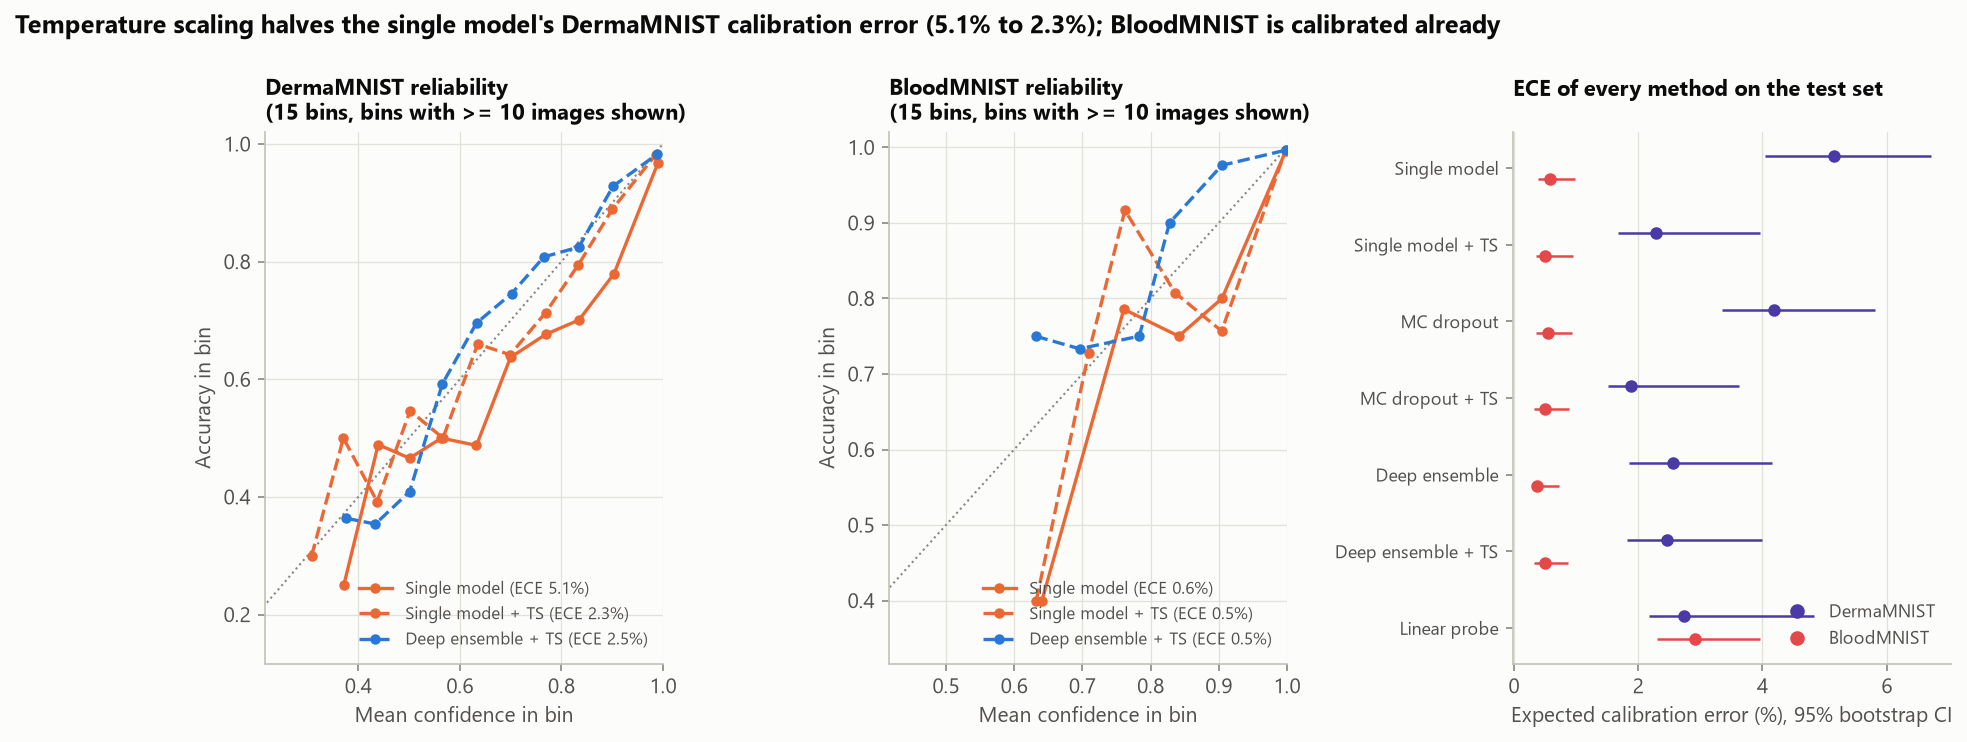

In [11]:
display(Image(FIG / '02_calibration.png'))

## 6. Selective prediction

Sorting test images by 1 - max probability and deferring the least certain ones lowers the error rate of the
answered images for every method; only the ensemble moves the curve, mostly between 60% and 95% coverage (at 80%
coverage: 92.6% accuracy vs 91.2%). A perfect ranking of the ensemble's errors would give an AURC of 1.32% against
the achieved 3.51%. Predictive entropy ranks about as well as 1 - max probability; mutual information (member or
pass disagreement) ranks worse.

Deferral is concentrated on the rare classes: answering 80% of DermaMNIST images defers 43% of melanomas and 56% of
actinic keratoses but 9% of nevi, and 39% of the melanomas that are answered are still wrong.

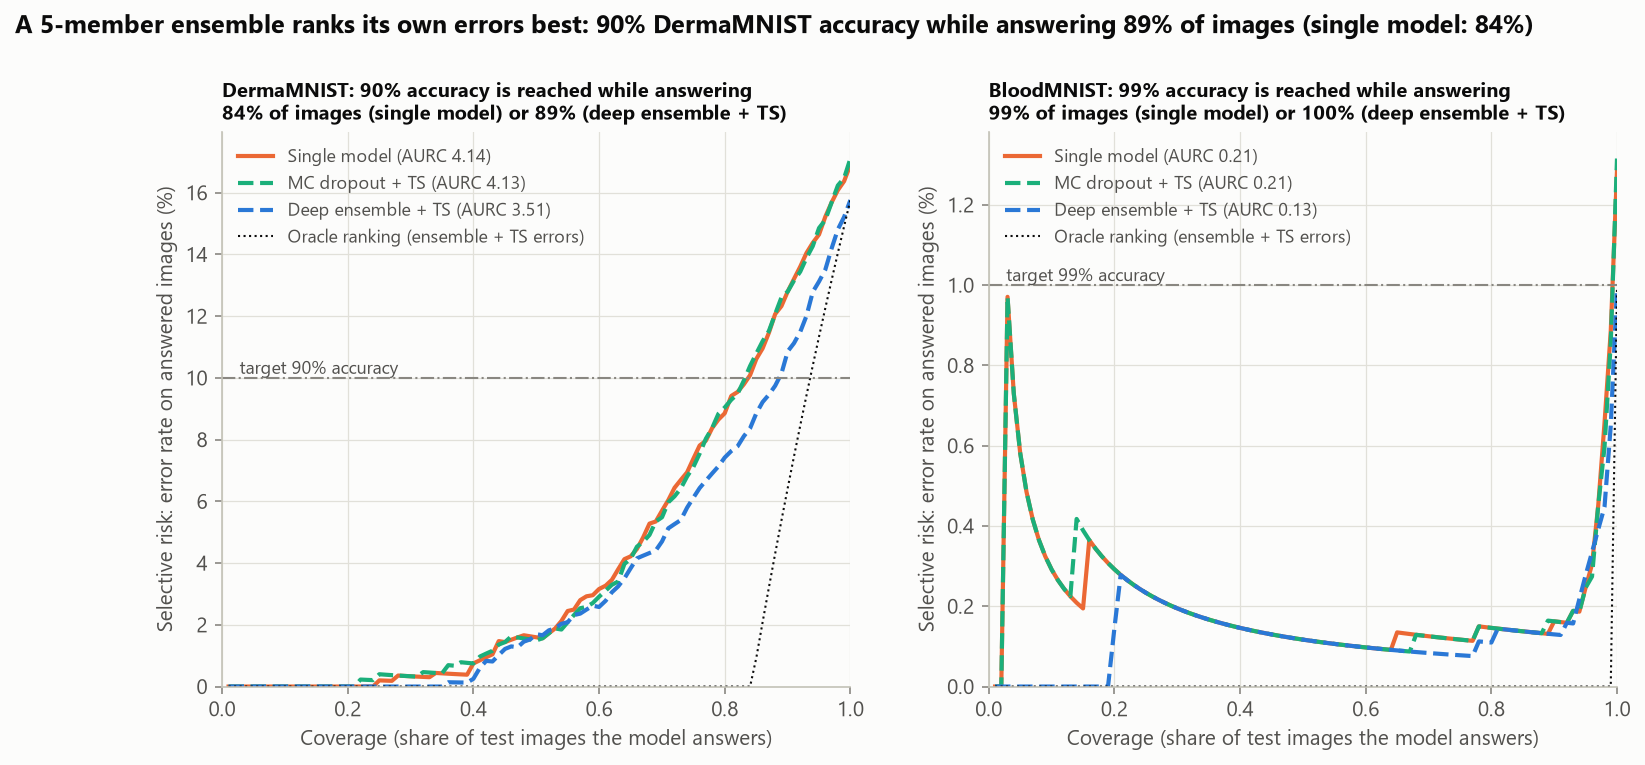

In [12]:
display(Image(FIG / '01_risk_coverage.png'))

In [13]:
sc = pd.read_csv(RES / 'uncertainty_scores.csv')
sc.pivot_table(index=['dataset', 'method'], columns='score', values=['aurc', 'error_detection_auroc'], sort=False).round(4)

aurc                            error_detection_auroc                           
score                         1 - max prob entropy mutual information          1 - max prob entropy mutual information
dataset    method                                                                                                     
dermamnist Single model              0.041   0.041                NaN                 0.862   0.862                NaN
           Single model + TS         0.041   0.042                NaN                 0.863   0.861                NaN
           MC dropout                0.041   0.042              0.047                 0.866   0.865              0.841
           MC dropout + TS           0.041   0.042              0.051                 0.867   0.864              0.823
           Deep ensemble             0.035   0.036              0.048                 0.877   0.869              0.810
           Deep ensemble + TS        0.035   0.036              0.047                 0.877   0.869              0.812
bloodmnist Single model              0.002   0.002                NaN                 0.931   0.931                NaN
           Single model + TS         0.002   0.002                NaN                 0.931   0.931                NaN
           MC dropout                0.002   0.002              0.002                 0.933   0.933              0.931
           MC dropout + TS           0.002   0.002              0.002                 0.933   0.933              0.931
           Deep ensemble             0.001   0.001              0.001                 0.926   0.926              0.915
           Deep ensemble + TS        0.001   0.001              0.001                 0.925   0.925              0.918

In [14]:
d = pd.read_csv(RES / 'deferral_by_class.csv')
d.pivot_table(index=['dataset', 'class'], columns='method', values=['deferred_share', 'accuracy_all', 'accuracy_accepted'], sort=False).round(3)

deferred_share                    accuracy_all                    accuracy_accepted                   
method             Single model Deep ensemble + TS Single model Deep ensemble + TS      Single model Deep ensemble + TS
dataset    class                                                                                                       
dermamnist akiec          0.561              0.591        0.500              0.500             0.655              0.667
           bcc            0.398              0.505        0.767              0.748             0.871              0.863
           bkl            0.432              0.391        0.564              0.655             0.664              0.791
           df             0.391              0.565        0.696              0.652             0.929              0.900
           mel            0.426              0.430        0.561              0.552             0.609              0.614
           nv             0.090              0.081        0.944              0.950             0.979              0.981
           vasc           0.103              0.241        0.793              0.793             0.808              0.955
bloodmnist baso           0.234              0.148        0.988              0.996             1.000              1.000
           eosi           0.010              0.008        1.000              1.000             1.000              1.000
           eryth          0.209              0.154        0.981              0.987             1.000              1.000
           ig             0.453              0.511        0.979              0.981             1.000              1.000
           lymph          0.099              0.152        0.992              0.992             1.000              1.000
           mono           0.324              0.401        0.972              0.986             0.995              0.994
           neut           0.260              0.212        0.980              0.982             0.994              0.996
           plt            0.011              0.015        1.000              1.000             1.000              1.000

## 7. How many members or passes?

Every added ensemble member lowers DermaMNIST NLL (0.485, 0.445, 0.433, 0.421, 0.415) and AURC (4.14% to 3.51%);
five members show no plateau yet. MC dropout converges by about 20 passes, at the deterministic single model's
AURC, with a slightly lower NLL; a single stochastic pass is worse than the deterministic model.

In [15]:
sz = pd.read_csv(RES / 'ensemble_size.csv')
sz.pivot_table(index=['dataset', 'family', 'n'], columns='temperature_scaled', values=['accuracy', 'nll', 'ece', 'aurc']).round(4)

accuracy          aurc           ece           nll       
temperature_scaled             False  True   False  True   False  True   False  True 
dataset    family        n                                                           
bloodmnist Deep ensemble 1     0.987  0.987  0.002  0.002  0.006  0.005  0.048  0.046
                         2     0.988  0.988  0.001  0.001  0.005  0.005  0.040  0.040
                         3     0.989  0.989  0.002  0.002  0.003  0.004  0.039  0.039
                         4     0.989  0.989  0.001  0.001  0.005  0.006  0.040  0.043
                         5     0.990  0.990  0.001  0.001  0.004  0.005  0.040  0.042
           MC dropout    1     0.987  0.987  0.002  0.002  0.005  0.004  0.047  0.046
                         2     0.987  0.987  0.002  0.002  0.007  0.006  0.048  0.047
                         5     0.988  0.988  0.002  0.002  0.006  0.004  0.046  0.045
                         10    0.987  0.987  0.002  0.002  0.005  0.004  0.045  0.045
                         20    0.987  0.987  0.002  0.002  0.005  0.005  0.046  0.045
                         50    0.987  0.987  0.002  0.002  0.005  0.005  0.046  0.045
dermamnist Deep ensemble 1     0.831  0.831  0.041  0.041  0.051  0.023  0.485  0.460
                         2     0.835  0.836  0.039  0.039  0.027  0.026  0.445  0.442
                         3     0.838  0.838  0.038  0.038  0.019  0.019  0.433  0.432
                         4     0.840  0.840  0.036  0.035  0.029  0.029  0.421  0.420
                         5     0.842  0.842  0.035  0.035  0.026  0.025  0.415  0.415
           MC dropout    1     0.827  0.827  0.044  0.044  0.053  0.017  0.505  0.478
                         2     0.825  0.825  0.043  0.043  0.050  0.020  0.490  0.469
                         5     0.829  0.829  0.042  0.042  0.044  0.022  0.482  0.464
                         10    0.828  0.828  0.042  0.042  0.044  0.019  0.477  0.461
                         20    0.829  0.829  0.042  0.041  0.043  0.020  0.474  0.459
                         50    0.829  0.829  0.041  0.041  0.042  0.019  0.473  0.459

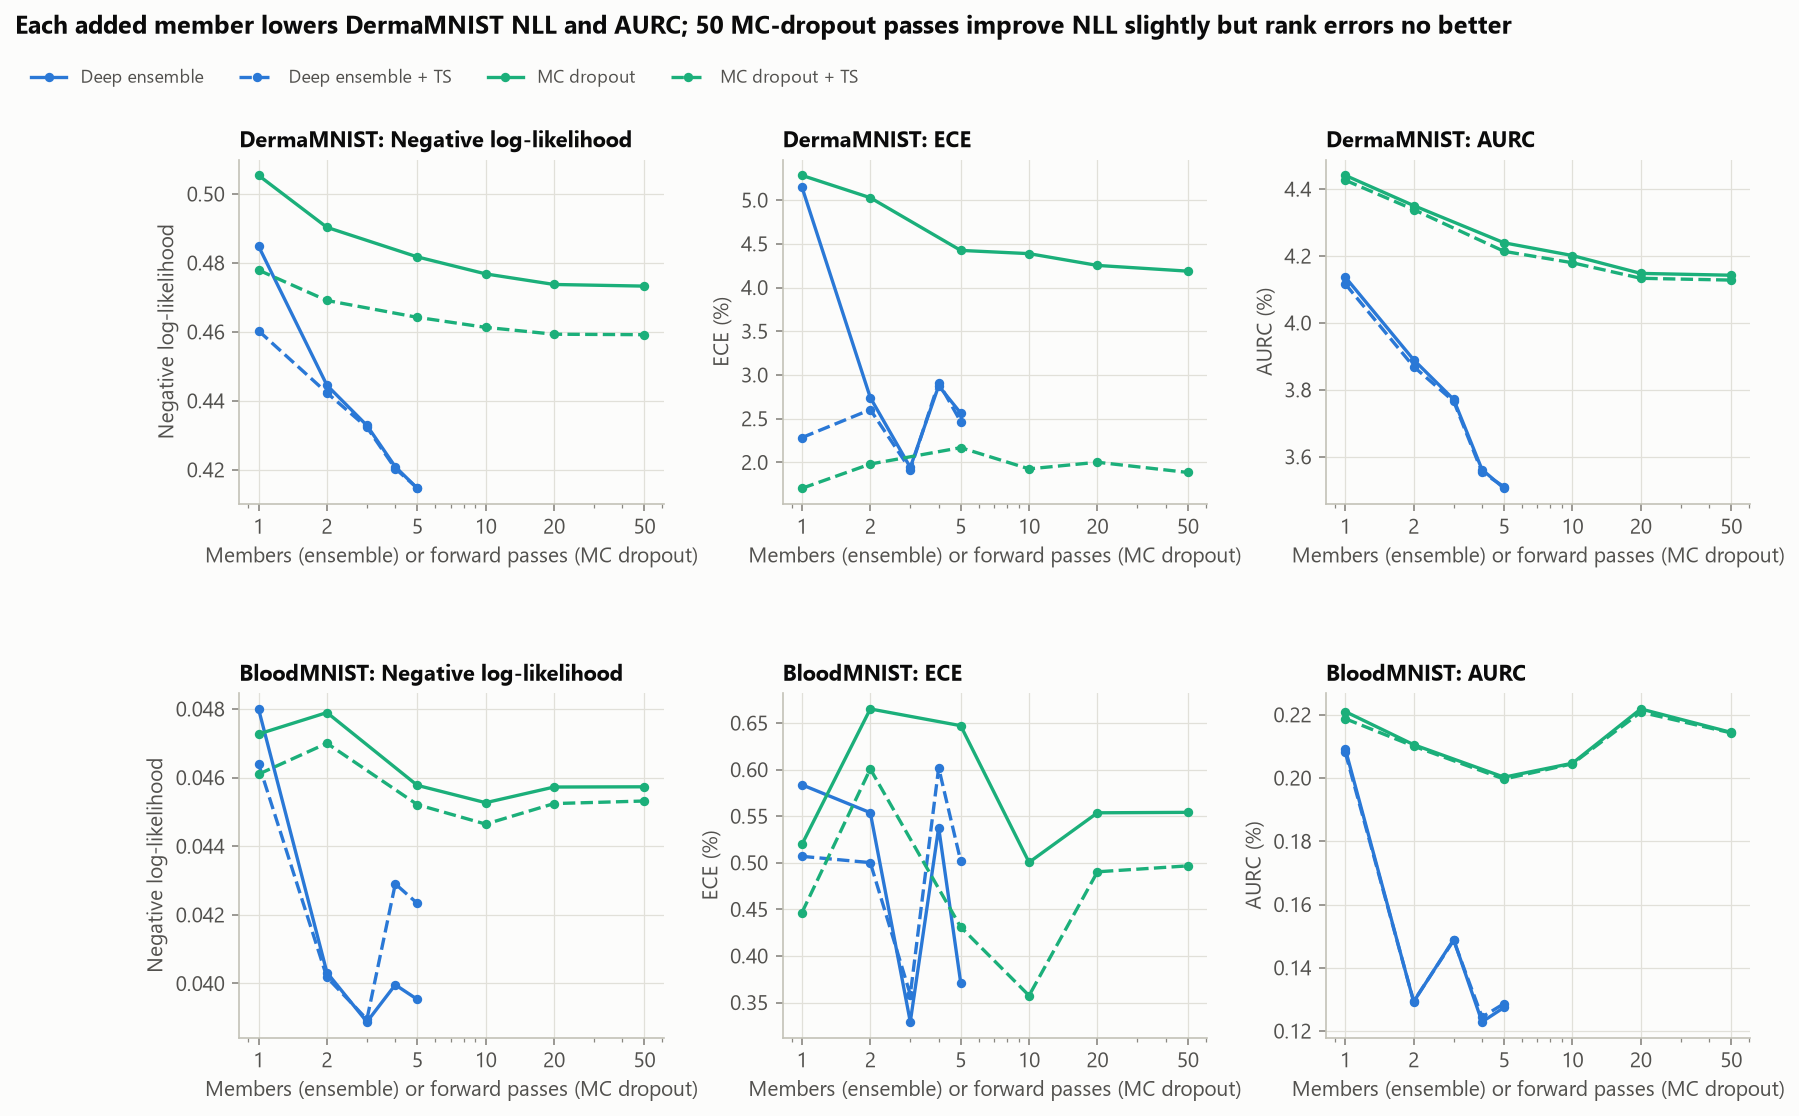

In [16]:
display(Image(FIG / '08_ensemble_size.png'))

## 8. Corrupted images

With the deferral threshold fixed on clean validation images (answering 80% of them), the two data sets behave in
opposite ways:

- **BloodMNIST.** Corrupted images lower the models' confidence: on average only 21% of corrupted images are
  answered. The ensemble is right on at least 99.1% of what it answers at every severity; the single model drops to 84.3% at
  the highest severity.
- **DermaMNIST.** The models keep answering about 70% of corrupted images, and only 68-72% of those answers are
  right (91-93% on clean images). Under contrast loss the members end up calling (almost) every lesion a nevus with
  low entropy, and answer all of them.

Contrast loss is the most damaging corruption (BloodMNIST accuracy falls to 40-42% at the mildest level), blur the
gentlest. The ensemble's accuracy advantage under corruption comes mostly from brightness and mild noise on
DermaMNIST; at the strongest noise level it is worse than the single model. Temperature scaling, fitted on clean
data, reduces ECE under corruption only partly.

In [17]:
cor = pd.read_csv(RES / 'corruption_results.csv')
cor.groupby(['dataset', 'method', 'severity'])[['accuracy', 'ece', 'aurc', 'mean_entropy']].mean().unstack('severity')['accuracy'].round(3)

severity                           0      1      2      3      4      5
dataset    method                                                      
bloodmnist Deep ensemble       0.990  0.778  0.678  0.525  0.415  0.309
           Deep ensemble + TS  0.990  0.778  0.679  0.526  0.415  0.307
           MC dropout          0.987  0.776  0.661  0.528  0.406  0.322
           MC dropout + TS     0.987  0.776  0.661  0.528  0.406  0.321
           Single model        0.987  0.776  0.661  0.528  0.406  0.321
           Single model + TS   0.987  0.776  0.661  0.528  0.406  0.321
dermamnist Deep ensemble       0.842  0.704  0.685  0.665  0.626  0.569
           Deep ensemble + TS  0.842  0.704  0.685  0.665  0.626  0.570
           MC dropout          0.829  0.685  0.634  0.588  0.584  0.588
           MC dropout + TS     0.829  0.685  0.635  0.588  0.584  0.588
           Single model        0.831  0.684  0.632  0.588  0.586  0.591
           Single model + TS   0.831  0.684  0.632  0.588  0.586  0.591

In [18]:
cor.groupby(['dataset', 'method', 'severity'])[['ece']].mean().unstack('severity')['ece'].round(3)

severity                           0      1      2      3      4      5
dataset    method                                                      
bloodmnist Deep ensemble       0.004  0.117  0.164  0.251  0.343  0.392
           Deep ensemble + TS  0.005  0.129  0.184  0.276  0.372  0.420
           MC dropout          0.006  0.149  0.222  0.302  0.400  0.456
           MC dropout + TS     0.005  0.147  0.218  0.297  0.394  0.450
           Single model        0.006  0.155  0.232  0.316  0.418  0.479
           Single model + TS   0.005  0.148  0.220  0.301  0.401  0.462
dermamnist Deep ensemble       0.026  0.072  0.096  0.138  0.182  0.270
           Deep ensemble + TS  0.025  0.073  0.098  0.140  0.183  0.271
           MC dropout          0.042  0.133  0.185  0.257  0.233  0.222
           MC dropout + TS     0.019  0.098  0.150  0.221  0.199  0.190
           Single model        0.051  0.149  0.204  0.278  0.257  0.245
           Single model + TS   0.023  0.101  0.156  0.228  0.208  0.197

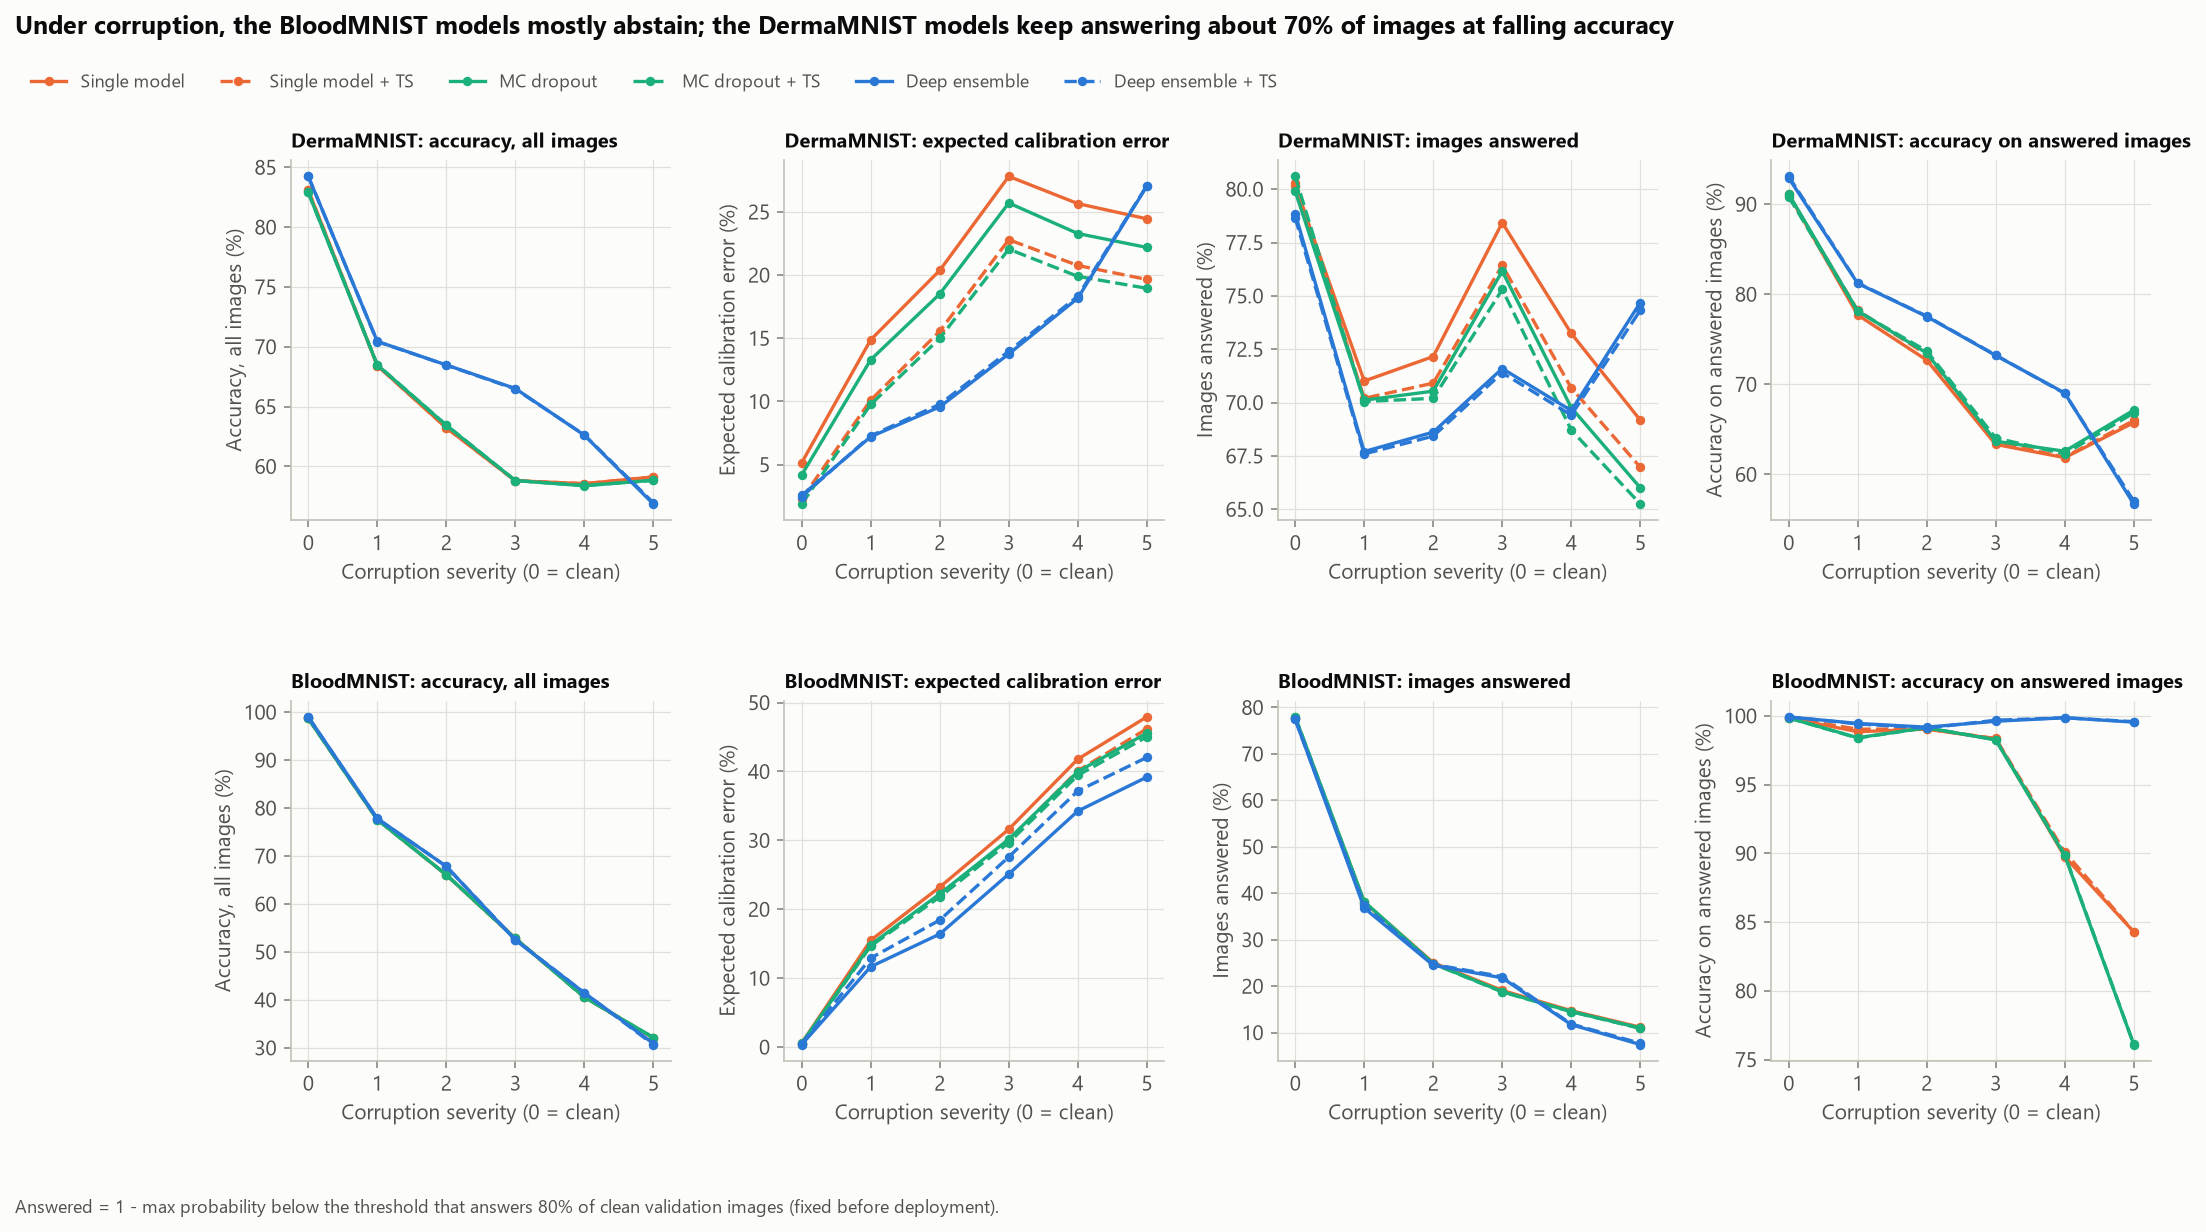

In [19]:
display(Image(FIG / '03_corruptions.png'))

In [20]:
cor[cor.method.isin(['Single model', 'Deep ensemble + TS'])].pivot_table(index=['dataset', 'corruption', 'severity'],
    columns='method', values=['accuracy', 'ece']).round(3)

accuracy                             ece             
method                             Deep ensemble + TS Single model Deep ensemble + TS Single model
dataset    corruption     severity                                                                
bloodmnist brightness     1                     0.939        0.925              0.016        0.036
                          2                     0.773        0.717              0.110        0.175
                          3                     0.645        0.564              0.193        0.311
                          4                     0.451        0.330              0.366        0.547
                          5                     0.233        0.178              0.570        0.753
           contrast       1                     0.400        0.422              0.358        0.406
                          2                     0.282        0.286              0.480        0.518
                          3                     0.253        0.286              0.479        0.478
                          4                     0.185        0.293              0.504        0.386
                          5                     0.139        0.294              0.533        0.340
           gaussian_blur  1                     0.974        0.966              0.006        0.019
                          2                     0.888        0.876              0.057        0.082
                          3                     0.815        0.810              0.116        0.136
                          4                     0.724        0.723              0.178        0.192
                          5                     0.611        0.643              0.236        0.227
           gaussian_noise 1                     0.799        0.793              0.136        0.159
                          2                     0.771        0.763              0.090        0.153
                          3                     0.390        0.454              0.316        0.339
                          4                     0.299        0.278              0.439        0.546
                          5                     0.244        0.168              0.343        0.597
           none           0                     0.990        0.987              0.005        0.006
dermamnist brightness     1                     0.814        0.779              0.023        0.105
                          2                     0.737        0.688              0.073        0.172
                          3                     0.692        0.586              0.086        0.218
                          4                     0.652        0.523              0.137        0.229
                          5                     0.659        0.557              0.187        0.200
           contrast       1                     0.556        0.608              0.201        0.236
                          2                     0.652        0.656              0.174        0.248
                          3                     0.670        0.671              0.264        0.293
                          4                     0.669        0.669              0.317        0.326
                          5                     0.669        0.669              0.323        0.328
           gaussian_blur  1                     0.835        0.819              0.026        0.066
                          2                     0.814        0.794              0.033        0.102
                          3                     0.784        0.766              0.071        0.144
                          4                     0.728        0.710              0.160        0.223
                          5                     0.692        0.683              0.238        0.280
           gaussian_noise 1                     0.612        0.530              0.041        0.188
                          2                     0.536        0.391              0.111

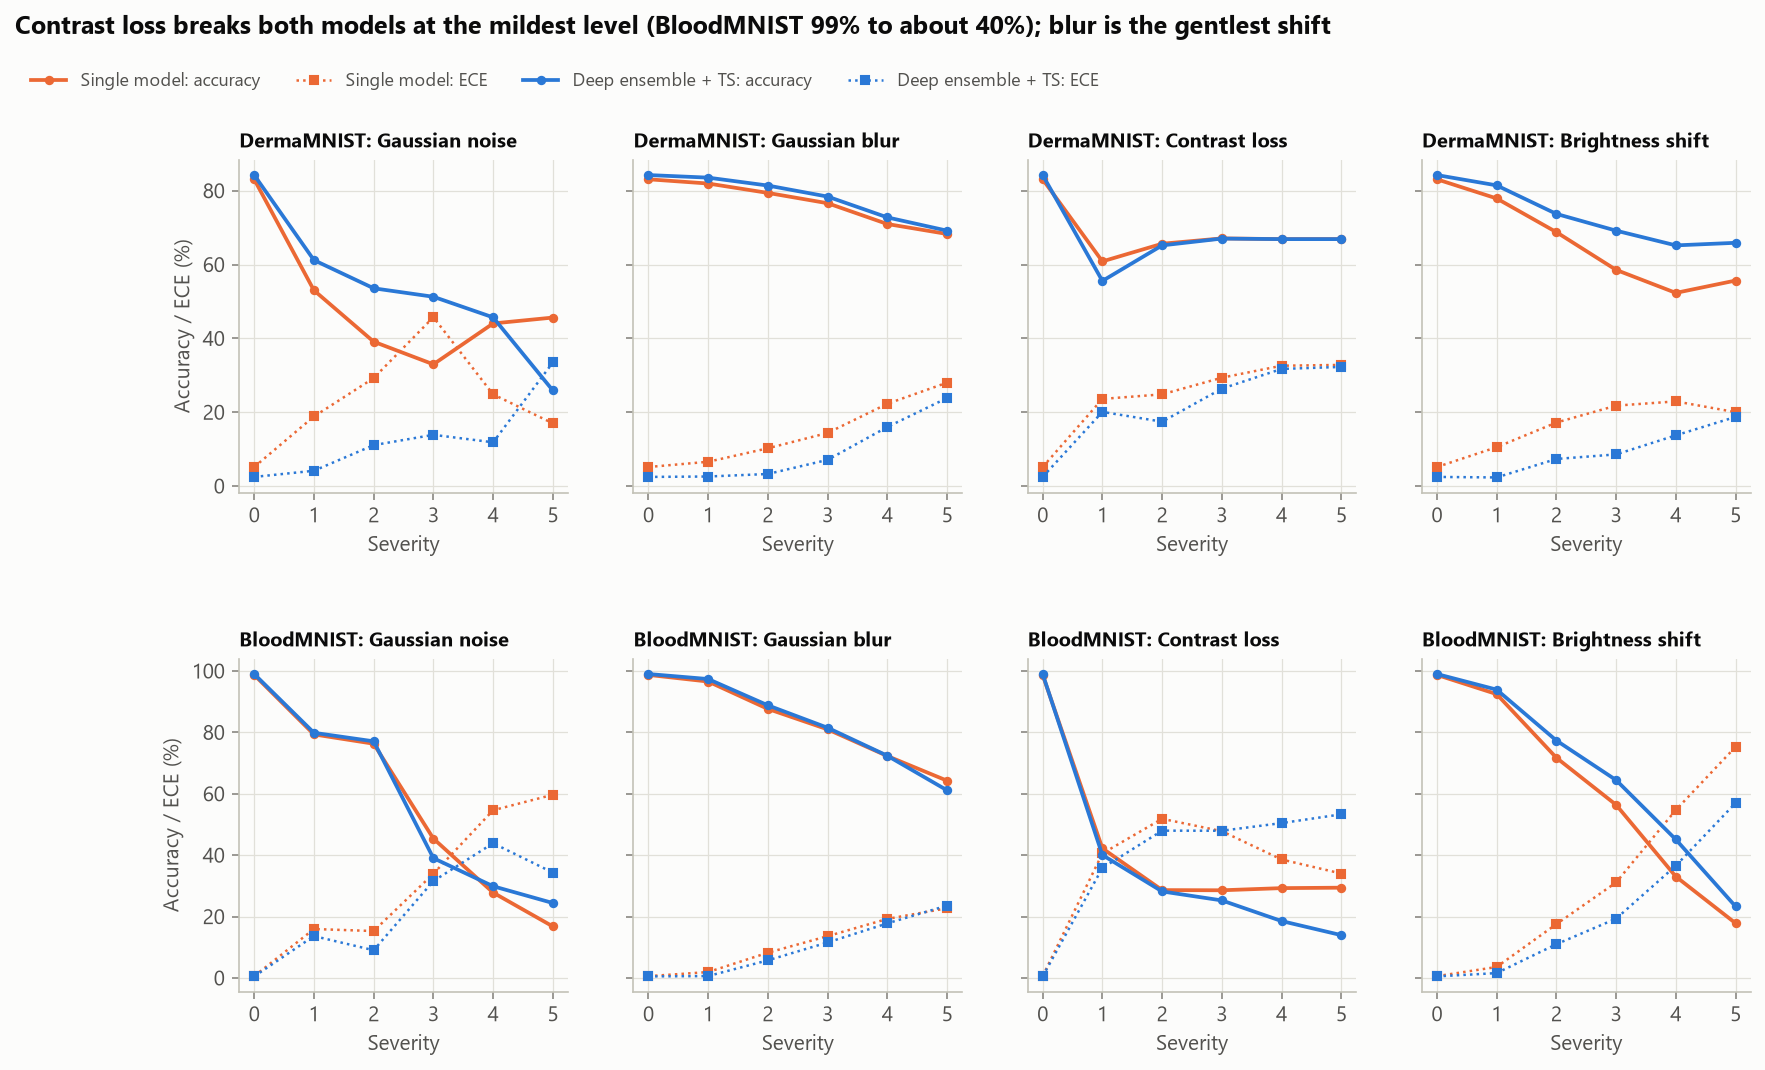

In [21]:
display(Image(FIG / '04_corruption_types.png'))

## 9. Images from the other data set

The BloodMNIST models flag skin images: AUROC 0.84 for the single model and 0.93 for the ensemble (0.94 with mutual
information), and the ensemble answers only 8% of them at the in-distribution threshold. The DermaMNIST models fail
in the opposite direction: they are more confident on blood-cell images (mean confidence 0.97-0.99) than on skin
lesions, label 99% of them "vascular lesion" and answer 98-99% of them; every score separates the two sets inversely
(AUROC 0.18-0.39). Confidence-based deferral needs a separate input or modality check in front of it.

In [22]:
pd.read_csv(RES / 'ood_detection.csv').round(3)

,dataset,ood_dataset,method,score,auroc,id_accepted,ood_accepted,ood_mean_confidence,ood_top_class,ood_top_class_share
0,dermamnist,bloodmnist,Single model,1 - max prob,0.182,0.801,0.989,0.990,vasc,0.994
1,dermamnist,bloodmnist,Single model,entropy,0.182,0.798,0.987,0.990,vasc,0.994
2,dermamnist,bloodmnist,Single model + TS,1 - max prob,0.180,0.803,0.988,0.982,vasc,0.994
3,dermamnist,bloodmnist,Single model + TS,entropy,0.181,0.808,0.987,0.982,vasc,0.994
4,dermamnist,bloodmnist,MC dropout,1 - max prob,0.240,0.799,0.985,0.983,vasc,0.994
5,dermamnist,bloodmnist,MC dropout,entropy,0.242,0.804,0.982,0.983,vasc,0.994
6,dermamnist,bloodmnist,MC dropout,mutual information,0.351,0.800,0.897,0.983,vasc,0.994
7,dermamnist,bloodmnist,MC dropout + TS,1 - max prob,0.228,0.806,0.985,0.975,vasc,0.994
8,dermamnist,bloodmnist,MC dropout + TS,entropy,0.230,0.809,0.983,0.975,vasc,0.994
9,dermamnist,bloodmnist,MC dropout + TS,mutual information,0.387,0.811,0.850,0.975,vasc,0.994


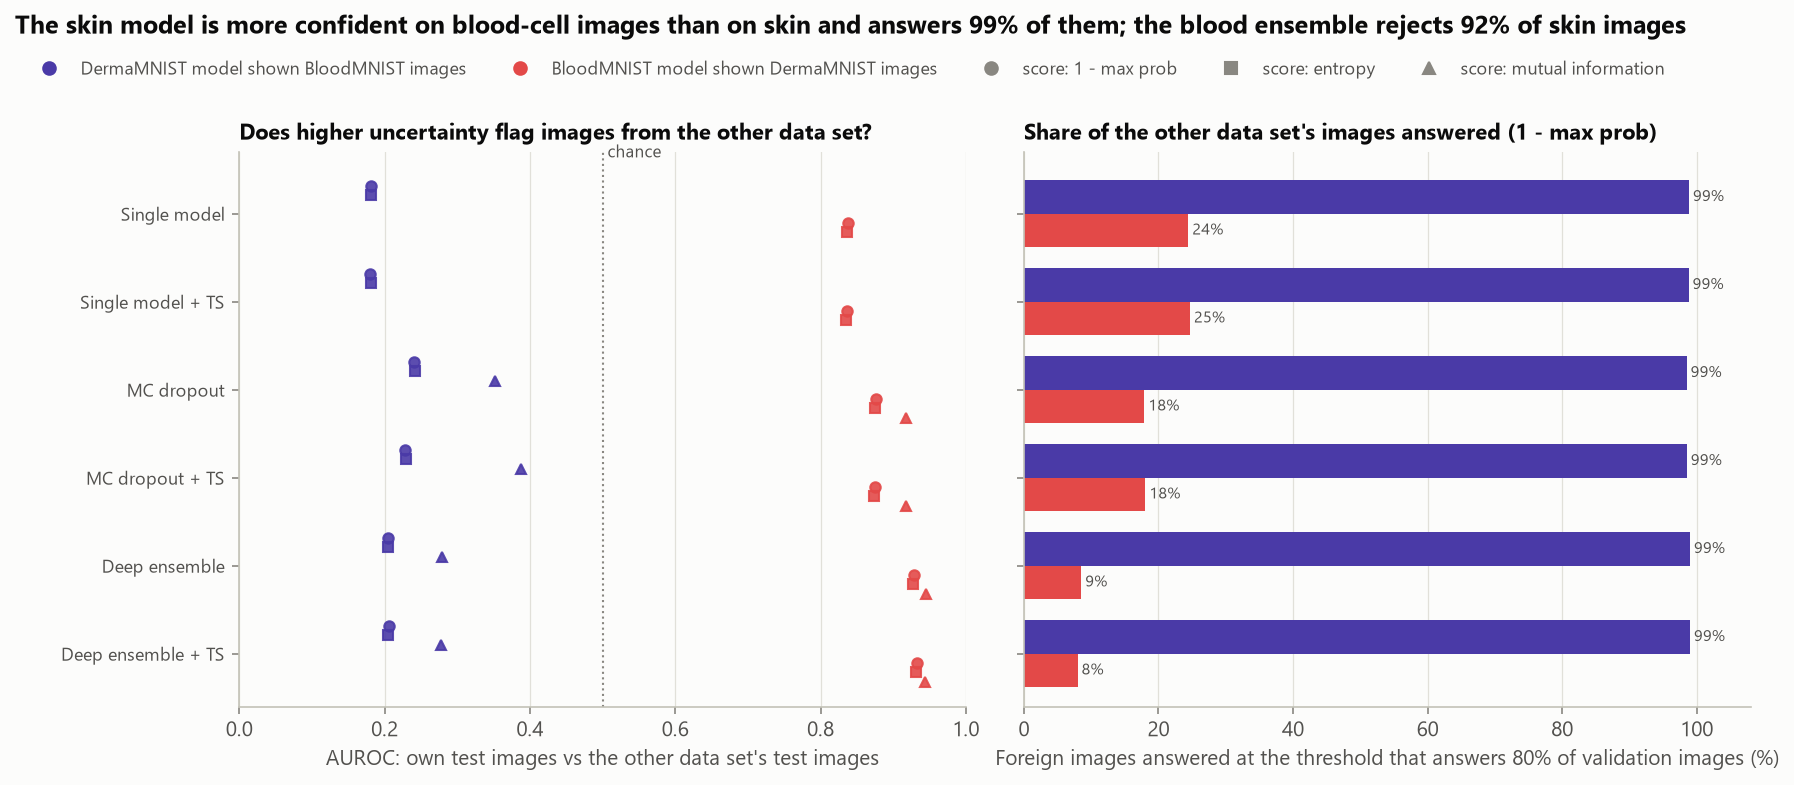

In [23]:
display(Image(FIG / '05_ood.png'))

## 10. Class imbalance

Post-hoc logit adjustment (dividing the probabilities by the class prior) raises the DermaMNIST single model's
melanoma recall from 56% to 67% and balanced accuracy from 0.689 to 0.724, at a cost of 5 points of accuracy; on the
ensemble it reaches the highest balanced accuracy (0.755) and 74% melanoma recall, at 0.754 accuracy. The
class-weighted loss lands in between (0.807 accuracy, 0.728 balanced accuracy) and needs temperature scaling to be
calibrated (ECE 5.3% to 1.5%). Every rebalancing moves errors from rare classes onto nevi rather than removing them.

In [24]:
pd.read_csv(RES / 'imbalance.csv')[['dataset', 'method', 'accuracy', 'balanced_accuracy', 'auc', 'nll', 'ece', 'aurc']]

,dataset,method,accuracy,balanced_accuracy,auc,nll,ece,aurc
0,dermamnist,Single model,0.831,0.689,0.965,0.485,0.051,0.041
1,dermamnist,Single model + logit adjustment,0.779,0.724,0.959,0.605,0.060,0.065
2,dermamnist,Class-weighted loss,0.807,0.728,0.960,0.529,0.053,0.055
3,dermamnist,Class-weighted loss + TS,0.807,0.728,0.960,0.506,0.015,0.055
4,dermamnist,Deep ensemble + TS,0.842,0.693,0.971,0.415,0.025,0.035
5,dermamnist,Deep ensemble + TS + logit adjustment,0.754,0.755,0.964,0.603,0.041,0.075


In [25]:
pd.read_csv(RES / 'imbalance_per_class.csv').pivot_table(index=['class'], columns='method', values='recall', sort=False).round(3)

method,Single model,Single model + logit adjustment,Class-weighted loss,Class-weighted loss + TS,Deep ensemble + TS,Deep ensemble + TS + logit adjustment
class,,,,,,
akiec,0.500,0.606,0.591,0.591,0.500,0.682
bcc,0.767,0.757,0.816,0.816,0.748,0.680
bkl,0.564,0.595,0.623,0.623,0.655,0.673
df,0.696,0.739,0.739,0.739,0.652,0.739
mel,0.561,0.673,0.623,0.623,0.552,0.740
nv,0.944,0.836,0.879,0.879,0.950,0.774
vasc,0.793,0.862,0.828,0.828,0.793,1.000


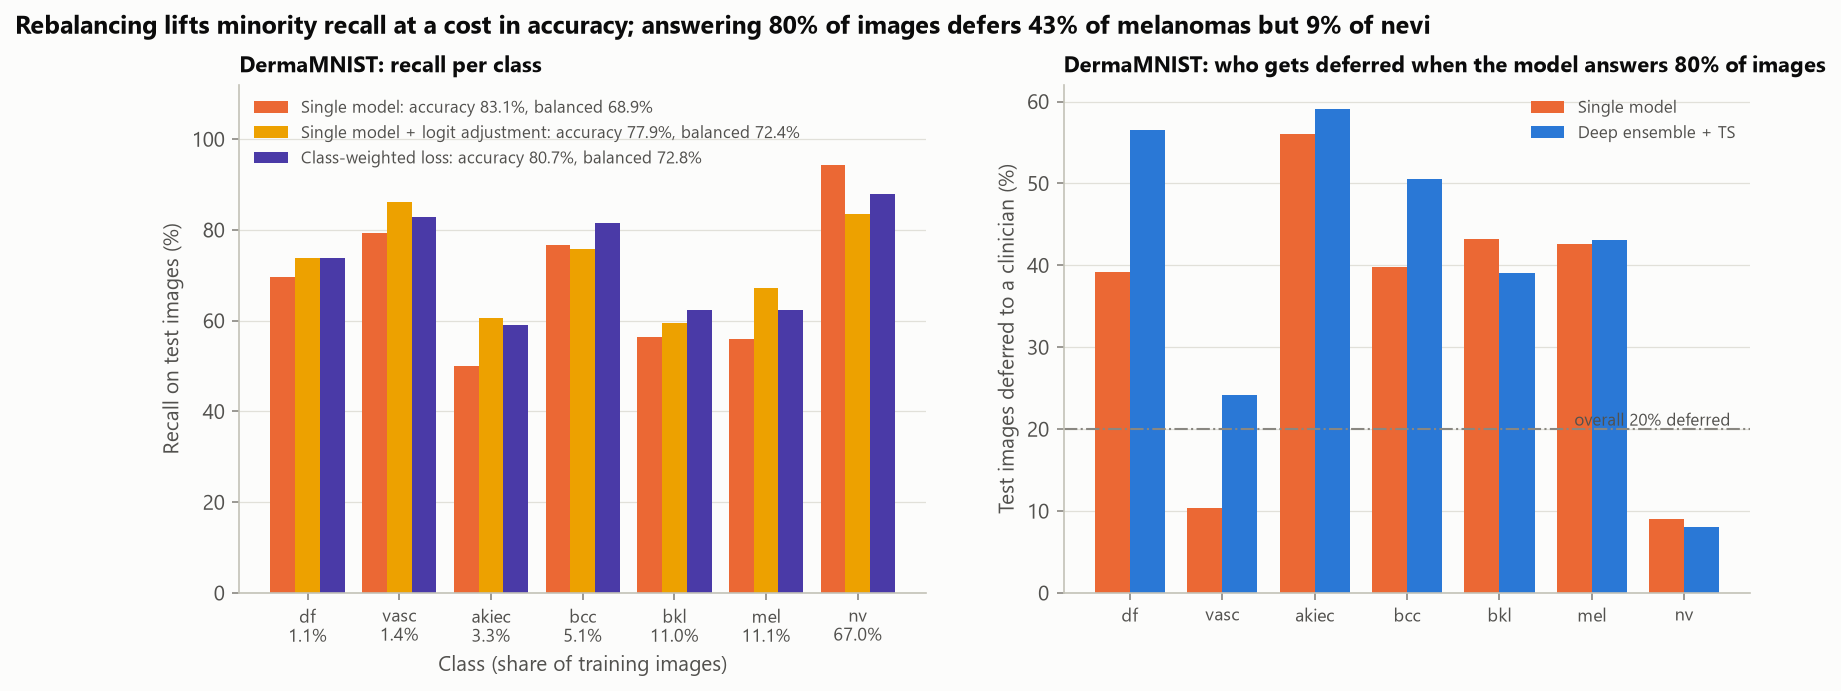

In [26]:
display(Image(FIG / '07_imbalance.png'))

## 11. Grad-CAM

The maps come from layer3 of member 0 (a 4 x 4 grid at 64 pixels). Re-initialising only the final layer drops their
rank correlation with the original maps to 0.11 on both data sets, and re-initialising layer4 as well to about 0, so
the maps depend on the trained weights. BloodMNIST maps put 47% of their mass in the central quarter of the image,
where the cell is (uniform: 25%); DermaMNIST maps only 31%, and several confident nevus predictions are driven by
the skin around the lesion or the image border.

In [27]:
pd.read_csv(RES / 'gradcam_sanity.csv')

,dataset,randomized,images,mean_spearman,median_spearman,share_spearman_above_0_5,mean_centre_share,uniform_centre_share
0,dermamnist,none (trained model),300,1.000,1.000,1.000,0.311,0.25
1,dermamnist,fc,300,0.108,0.112,0.200,0.277,0.25
2,dermamnist,fc + layer4,300,-0.078,-0.100,0.053,0.222,0.25
3,dermamnist,fc + layer4 + layer3,300,-0.015,-0.034,0.020,0.261,0.25
4,bloodmnist,none (trained model),300,1.000,1.000,1.000,0.472,0.25
5,bloodmnist,fc,300,0.111,0.100,0.230,0.270,0.25
6,bloodmnist,fc + layer4,300,0.011,-0.045,0.110,0.291,0.25
7,bloodmnist,fc + layer4 + layer3,300,0.028,0.034,0.027,0.292,0.25


In [28]:
pd.read_csv(RES / 'gradcam_examples.csv')

,dataset,order,category,test_index,label,prediction,confidence_single,ensemble_prediction,confidence_ensemble_ts
0,dermamnist,0,confident and correct,1296,nv,nv,0.999,nv,1.000
1,dermamnist,1,confident and correct,1018,nv,nv,0.997,nv,0.999
2,dermamnist,2,confident and correct,1692,nv,nv,0.997,nv,0.999
3,dermamnist,3,confident but wrong,1332,bkl,nv,0.999,nv,0.973
4,dermamnist,4,confident but wrong,1117,bkl,nv,0.999,nv,0.966
5,dermamnist,5,confident but wrong,1351,bkl,nv,0.997,nv,0.967
6,dermamnist,6,most uncertain (ensemble),45,bcc,bcc,0.441,bcc,0.271
7,dermamnist,7,most uncertain (ensemble),411,bcc,vasc,0.672,bcc,0.304
8,dermamnist,8,most uncertain (ensemble),586,akiec,nv,0.450,vasc,0.311
9,bloodmnist,0,confident and correct,2196,eosi,eosi,1.000,eosi,1.000


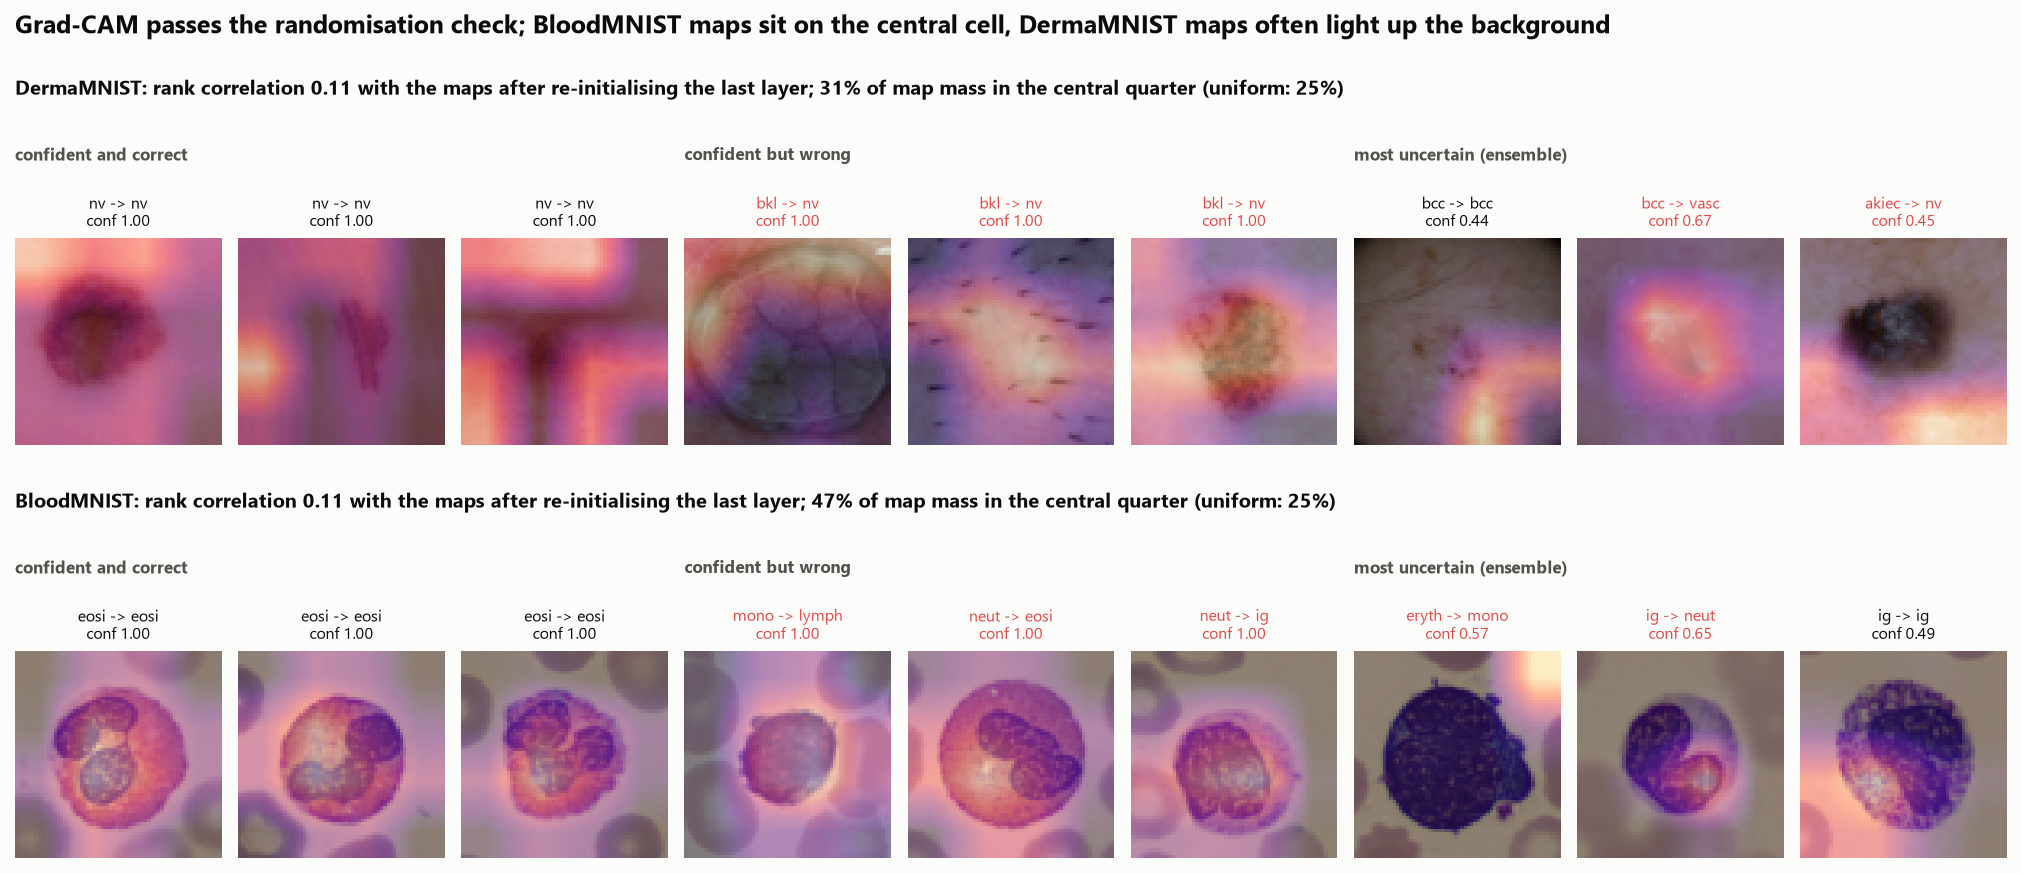

In [29]:
display(Image(FIG / '06_gradcam.png'))

## Takeaways

1. A five-member deep ensemble is the only method here that ranks its own errors better than a single model; it also
   gives the best NLL and AUC. Temperature scaling is enough for calibration on clean data.
2. Last-layer MC dropout adds nothing over a temperature-scaled single model.
3. Deferral based on confidence protects the BloodMNIST models under corruption but not the DermaMNIST models, and
   neither model's confidence can be trusted on images from a different modality.
4. Deferral and rebalancing both act mostly on the rare and clinically important DermaMNIST classes, so per-class
   reporting is needed alongside the averages.
5. The DermaMNIST numbers are likely optimistic because of known lesion-level leakage between its splits.